In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.preprocessing import MinMaxScaler

RANDOM_STATE = 42
DATA_DIR = "data"
FEATURES = ["sent_kb_s", "recv_kb_s", "idle_sec"]
LABEL_COL = "label"

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Data Loading

In [2]:
paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))

dfs = []
for p in paths:
    df = pd.read_csv(p)
    df["source"] = os.path.basename(p).replace(".csv", "")
    dfs.append(df)

data = pd.concat(dfs, ignore_index=True)
data = data.dropna(subset=FEATURES + [LABEL_COL])
data[LABEL_COL] = data[LABEL_COL].astype(int)

print(f"Total samples: {len(data)}")
print(f"Normal: {(data[LABEL_COL]==0).sum()} | Anomaly: {(data[LABEL_COL]==1).sum()}")

Total samples: 2520
Normal: 1980 | Anomaly: 540


## 2. Exploratory Analysis

**Normal scenarios (label=0):**
- `deep_idle` – system completely idle, minimal background activity
- `idle_with_background_noise` – idle with typical system processes (updates, sync)
- `normal_work` – active usage: browsing, typing, light applications
- `entertainment` – streaming video, high download traffic
- `normal_upload` – uploading files while actively working

**Attack scenarios (label=1):**
- `steady` – continuous high-bandwidth exfiltration (~500 KB/s)
- `bursty` – periodic exfiltration (3s on, 2s off pattern)
- `trickle` – low-and-slow exfiltration (~2 KB/s), designed to evade detection

CLASS DISTRIBUTION
Normal (0):   1980 samples
Anomaly (1):   540 samples

SAMPLES PER SCENARIO
bursty                          180 samples  [Anomaly]
deep_idle                       360 samples  [Normal]
entertainment                   360 samples  [Normal]
idle_with_backgorund_noise      360 samples  [Normal]
normal_upload                   180 samples  [Normal]
normal_work                     360 samples  [Normal]
steady                          180 samples  [Anomaly]
trickle                         180 samples  [Anomaly]
upload_normal                   360 samples  [Normal]


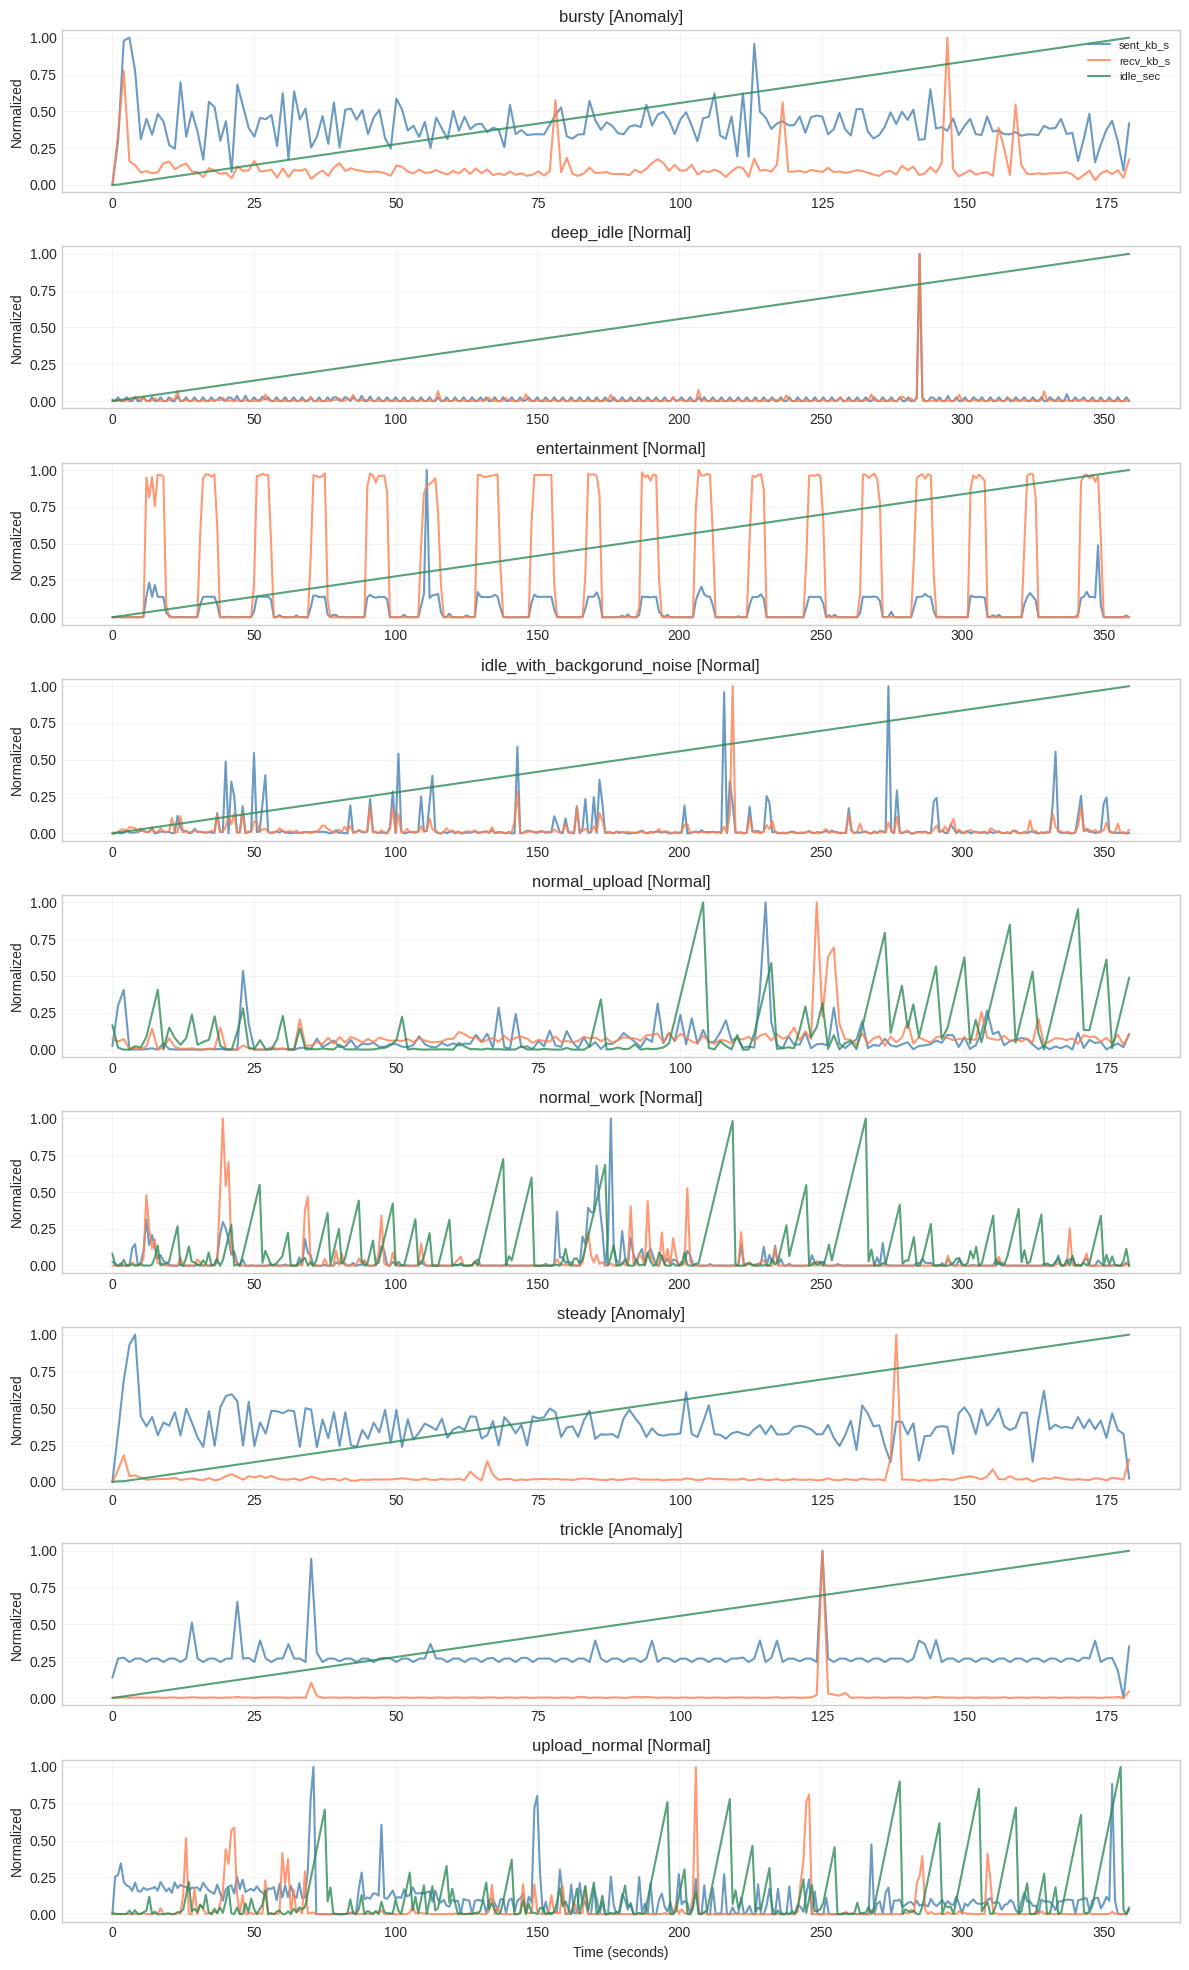

/tmp/ipykernel_140839/3829532677.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=labels, patch_artist=True)
/tmp/ipykernel_140839/3829532677.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=labels, patch_artist=True)
/tmp/ipykernel_140839/3829532677.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=labels, patch_artist=True)


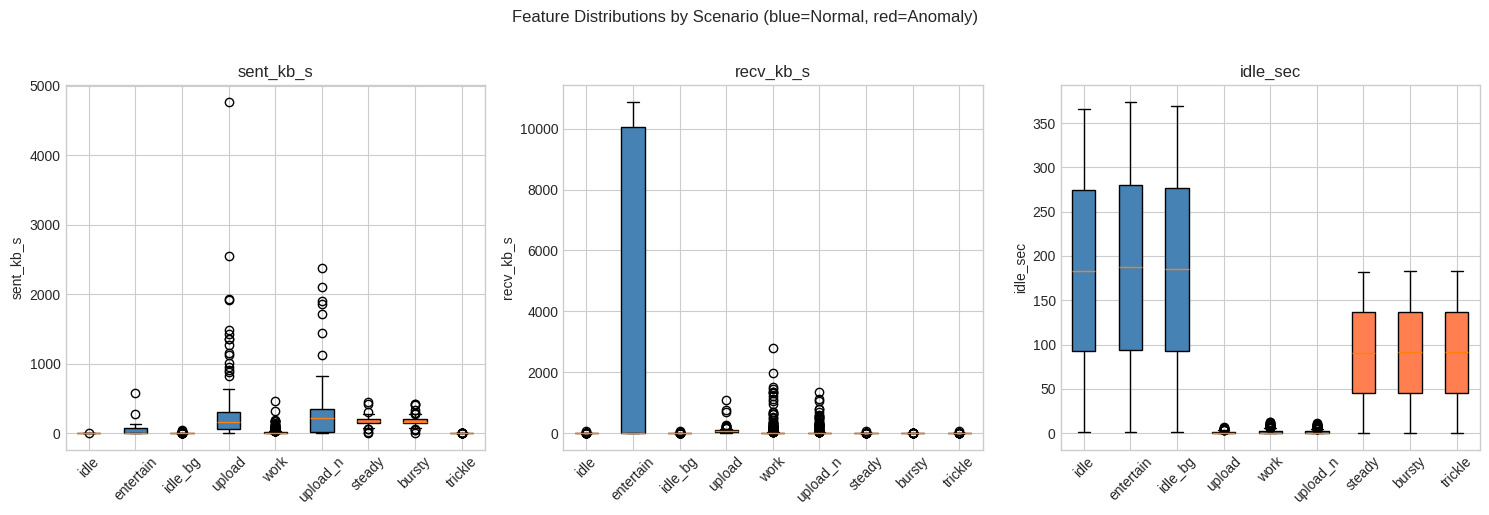

In [3]:
# Class distribution
print("="*50)
print("CLASS DISTRIBUTION")
print("="*50)
print(f"Normal (0):  {(data[LABEL_COL]==0).sum():>5} samples")
print(f"Anomaly (1): {(data[LABEL_COL]==1).sum():>5} samples")

# Samples per scenario
print("\n" + "="*50)
print("SAMPLES PER SCENARIO")
print("="*50)
for source in sorted(data["source"].unique()):
    subset = data[data["source"] == source]
    label = "Normal" if subset[LABEL_COL].iloc[0] == 0 else "Anomaly"
    print(f"{source:<30} {len(subset):>4} samples  [{label}]")

# Time series per scenario
scenarios = sorted(data["source"].unique())
n = len(scenarios)

fig, axes = plt.subplots(n, 1, figsize=(12, 2.2 * n), sharex=False)
if n == 1:
    axes = [axes]

scaler = MinMaxScaler()
colors = ["steelblue", "coral", "seagreen"]

for ax, source in zip(axes, scenarios):
    subset = data[data["source"] == source].reset_index(drop=True)
    scaled = scaler.fit_transform(subset[FEATURES])
    
    for feat, col, series in zip(FEATURES, colors, scaled.T):
        ax.plot(series, label=feat, color=col, alpha=0.8)
    
    label_type = "Anomaly" if subset[LABEL_COL].iloc[0] == 1 else "Normal"
    ax.set_title(f"{source} [{label_type}]")
    ax.set_ylabel("Normalized")
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# Feature distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

scenarios_sorted = data.groupby("source")[LABEL_COL].first().sort_values().index.tolist()
colors = ["steelblue" if data[data["source"]==s][LABEL_COL].iloc[0]==0 else "coral" for s in scenarios_sorted]

# Shortened labels
short_labels = {
    "deep_idle": "idle",
    "entertainment": "entertain",
    "idle_with_backgorund_noise": "idle_bg",
    "normal_upload": "upload",
    "normal_work": "work",
    "upload_normal": "upload_n",
    "steady": "steady",
    "bursty": "bursty",
    "trickle": "trickle"
}
labels = [short_labels.get(s, s) for s in scenarios_sorted]

for ax, feat in zip(axes, FEATURES):
    box_data = [data[data["source"] == s][feat] for s in scenarios_sorted]
    bp = ax.boxplot(box_data, labels=labels, patch_artist=True)
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
    ax.set_ylabel(feat)
    ax.set_title(feat)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Feature Distributions by Scenario (blue=Normal, red=Anomaly)", y=1.02)
plt.tight_layout()
plt.show()

## 3. Train/Test Split

In [4]:
X = data[FEATURES].values
y = data[LABEL_COL].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {len(y_train)} | Test: {len(y_test)}")
print(f"Train distribution - Normal: {(y_train==0).sum()}, Anomaly: {(y_train==1).sum()}")

Train: 1890 | Test: 630
Train distribution - Normal: 1485, Anomaly: 405


## 4. Model Training & Evaluation

In the context of network anomaly detection:

- **Precision** – Of all connections flagged as attacks, how many were actual attacks? Low precision means many false alarms, which wastes analyst time.
- **Recall** – Of all actual attacks, how many did we detect? Low recall means missed attacks, which is a security risk.
- **F1** – Harmonic mean of precision and recall. Useful when both false alarms and missed attacks are costly.

In [5]:
def evaluate(name, y_true, y_pred, show_plot=True):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    if show_plot:
        ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomaly"]).plot(cmap="Blues")
        plt.title(name)
        plt.show()
    
    return {"Model": name, "Precision": round(precision, 3), "Recall": round(recall, 3), 
            "F1": round(f1, 3), "TP": tp, "FP": fp, "TN": tn, "FN": fn}

### Logistic Regression

Starte Hyperparameter Tuning für Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Beste Parameter gefunden: {'clf__C': 0.001, 'clf__penalty': 'l2'}


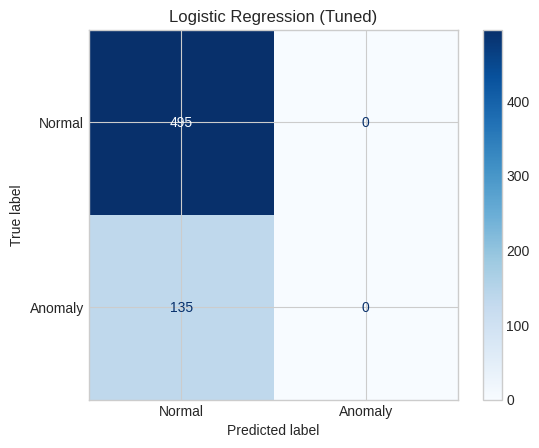

Precision: 0.000 | Recall: 0.000 | F1: 0.000


In [6]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
lr.fit(X_train, y_train)
res_lr = evaluate("Logistic Regression", y_test, lr.predict(X_test))
print(f"Precision: {res_lr['Precision']:.3f} | Recall: {res_lr['Recall']:.3f} | F1: {res_lr['F1']:.3f}")

### Random Forest

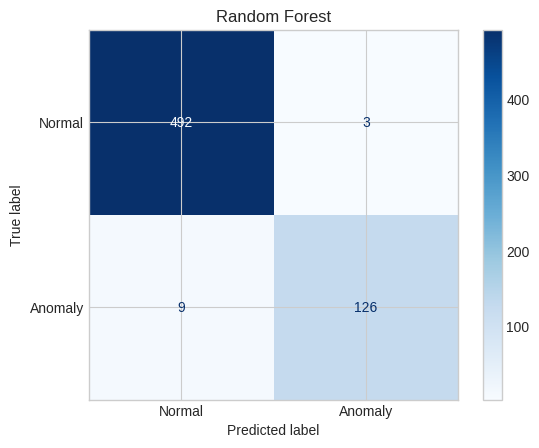

Precision: 0.977 | Recall: 0.933 | F1: 0.955


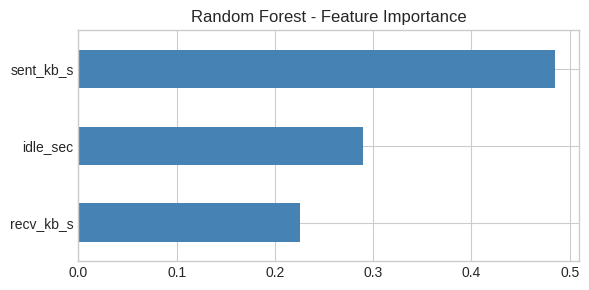

In [7]:
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
res_rf = evaluate("Random Forest", y_test, rf.predict(X_test))
print(f"Precision: {res_rf['Precision']:.3f} | Recall: {res_rf['Recall']:.3f} | F1: {res_rf['F1']:.3f}")

# Feature importance
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
imp.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Random Forest - Feature Importance")
plt.tight_layout()
plt.show()

### HBOS (Histogram-Based Outlier Score)

Tuning HBOS (Histogram-Based Outlier Score)...
--------------------------------------------------
Bins:   5 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
Bins:  10 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
Bins:  20 | F1: 0.012 | Recall: 0.007 | Precision: 0.026
Bins:  30 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
Bins:  50 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
Bins: 100 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
Bins: 200 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
--------------------------------------------------
Bester Wert: n_bins = 20 (F1: 0.012)


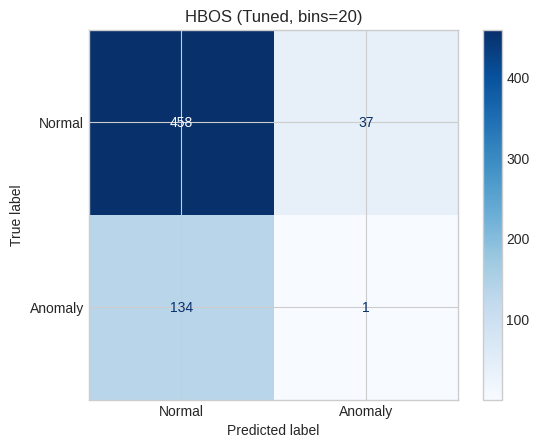

In [7]:
class SimpleHBOS:
    def __init__(self, n_bins=20):
        self.n_bins = n_bins
    
    def fit(self, X):
        self.edges_, self.probs_ = [], []
        for j in range(X.shape[1]):
            edges = np.linspace(X[:, j].min(), X[:, j].max(), self.n_bins + 1)
            hist, _ = np.histogram(X[:, j], bins=edges)
            self.edges_.append(edges)
            self.probs_.append(hist / hist.sum())
        return self
    
    def score_samples(self, X):
        scores = np.zeros(len(X))
        for j in range(X.shape[1]):
            bins = np.clip(np.digitize(X[:, j], self.edges_[j][1:-1]), 0, self.n_bins - 1)
            scores += -np.log(np.maximum(self.probs_[j][bins], 1e-10))
        return scores

X_normal = X_train[y_train == 0]
hbos = SimpleHBOS().fit(X_normal)

threshold_hbos = np.percentile(hbos.score_samples(X_normal), 95)
hbos_scores = hbos.score_samples(X_test)
hbos_pred = (hbos_scores > threshold_hbos).astype(int)

res_hbos = evaluate("HBOS", y_test, hbos_pred)
print(f"Precision: {res_hbos['Precision']:.3f} | Recall: {res_hbos['Recall']:.3f} | F1: {res_hbos['F1']:.3f}")

### K-Means (Distance-Based)

Tuning K-Means (Anzahl der Cluster)...
--------------------------------------------------
k:  2 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
k:  3 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
k:  4 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
k:  5 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
k:  8 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
k: 10 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
k: 15 | F1: 0.000 | Recall: 0.000 | Precision: 0.000
--------------------------------------------------
Bester Wert: k = 2 (F1: 0)


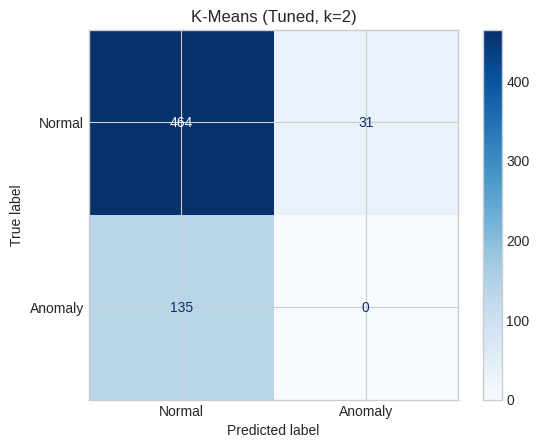

In [8]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_normal)

km_distances = kmeans.transform(X_test).min(axis=1)
threshold_km = np.percentile(kmeans.transform(X_normal).min(axis=1), 95)
km_pred = (km_distances > threshold_km).astype(int)

res_km = evaluate("K-Means", y_test, km_pred)
print(f"Precision: {res_km['Precision']:.3f} | Recall: {res_km['Recall']:.3f} | F1: {res_km['F1']:.3f}")

### Voting Ensemble (RF + HBOS)

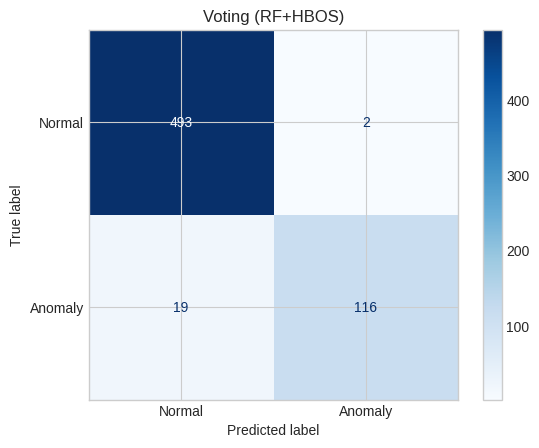

Precision: 0.983 | Recall: 0.859 | F1: 0.917


In [10]:
rf_proba = rf.predict_proba(X_test)[:, 1]
hbos_norm = (hbos_scores - hbos_scores.min()) / (hbos_scores.max() - hbos_scores.min())

vote_score = 0.5 * rf_proba + 0.5 * hbos_norm
vote_pred = (vote_score >= 0.5).astype(int)

res_vote = evaluate("Voting (RF+HBOS)", y_test, vote_pred)
print(f"Precision: {res_vote['Precision']:.3f} | Recall: {res_vote['Recall']:.3f} | F1: {res_vote['F1']:.3f}")

## 5. Results Comparison

,Model,Precision,Recall,F1,TP,FP,TN,FN
0,Logistic Regression,0.000,0.000,0.000,0,5,490,135
1,Random Forest,0.977,0.933,0.955,126,3,492,9
2,HBOS,0.026,0.007,0.012,1,37,458,134
3,K-Means,0.000,0.000,0.000,0,33,462,135
4,Voting (RF+HBOS),0.983,0.859,0.917,116,2,493,19


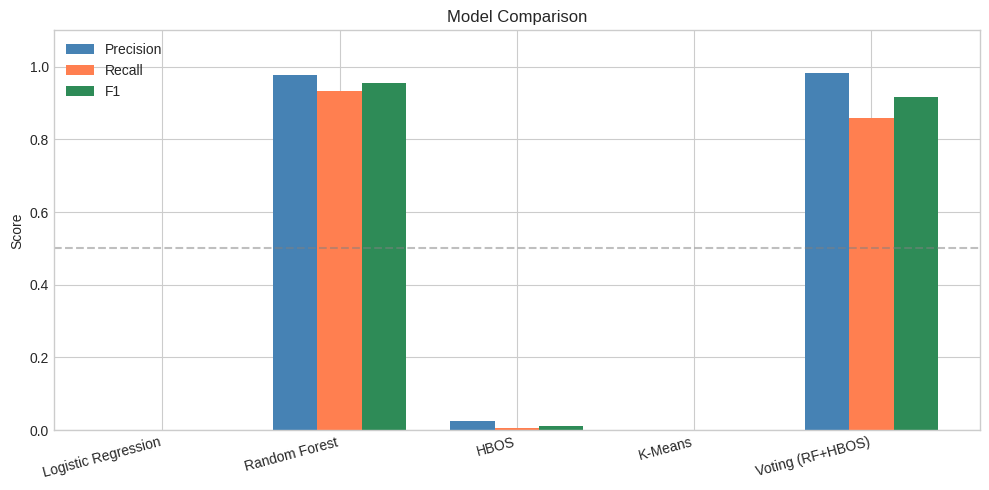

In [11]:
results = pd.DataFrame([res_lr, res_rf, res_hbos, res_km, res_vote])
results = results[["Model", "Precision", "Recall", "F1", "TP", "FP", "TN", "FN"]]
display(results)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(results))
width = 0.25

ax.bar(x - width, results["Precision"], width, label="Precision", color="steelblue")
ax.bar(x, results["Recall"], width, label="Recall", color="coral")
ax.bar(x + width, results["F1"], width, label="F1", color="seagreen")

ax.set_xticks(x)
ax.set_xticklabels(results["Model"], rotation=15, ha="right")
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Model Comparison")
ax.legend()
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Save Best Model

In [12]:
os.makedirs("models", exist_ok=True)
joblib.dump(rf, "models/model_rf.joblib")
print("Model saved: models/model_rf.joblib")

Model saved: models/model_rf.joblib
